# 数据分析与机器学习 · 第3—4课时
## Python数据分析基础

授课教师：谭彪 
西华大学建筑与土木工程学院

| 内容 | 时间 |
|---|---:|
| 环境配置演示：和鲸、本地VS Code与运行检查 | 20分钟 |
| Python基础：变量、数据类型、列表、字典、条件、循环、函数 | 45分钟 |
| 常用库的基本示例与流程预览 | 10分钟 |
| 保存、检查与回顾 | 5分钟 |
| **合计** | **80分钟** |

第一课时先看环境配置，再讲变量、数据类型和列表；第二课时从字典开始。Python部分包含修改代码、观察输出的时间。

库部分另有数据清洗、特征处理、分类、回归与评价的连续示例，可在后续课时继续展开。


## 一、环境配置演示（20分钟）

### 1. 和鲸在线运行（8分钟）

1. 登录和鲸，进入个人工作台。
2. 上传本文件，打开Notebook，连接**Python 3、CPU**环境。
3. 运行下面一格，应显示`3`。

和鲸入口：https://www.heywhale.com/  
完整操作见《和鲸在线使用指南》。启动前看资源单价和鲸币余额，使用结束后停止运行实例。


In [1]:
print(1 + 2)

3


### 2. 本地VS Code（10分钟）

1. 展示Miniconda安装入口和关键选项，再说明课程环境的名称`ml-course`。
2. 在Anaconda Prompt中创建、选用课程环境；库的安装见下一格。
3. VS Code安装Microsoft发布的**Python**、**Jupyter**扩展。
4. 打开`.py`文件，从**右下角**选择`ml-course`；打开本Notebook，从**右上角“选择内核”**选择`ml-course`。

创建、选用环境的命令在Anaconda Prompt中运行：

```text
conda create -n ml-course python=3.12 -y
conda activate ml-course
```

Anaconda下载：https://www.anaconda.com/download
Miniconda下载：https://repo.anaconda.com/miniconda/  
VS Code下载：https://code.visualstudio.com/download  
完整操作见《本地安装指南》。教师演示关键步骤后，用已准备好的环境继续运行课堂代码。


### 安装课程库

下面是Notebook代码格中的安装命令，开头保留英文感叹号。安装完成再继续。

`Successfully installed`表示装好了，`Requirement already satisfied`表示已经安装。安装后仍不能导入时，重启内核，再按顺序运行。


In [ ]:
!pip install numpy pandas matplotlib scipy scikit-learn nbformat nbconvert -i https://pypi.tuna.tsinghua.edu.cn/simple

### 3. 运行检查与数据准备（2分钟）

下面一格建立本课使用的`data`、`outputs`文件夹，并准备三条成绩数据。运行后看实际保存位置，课堂后面读表和保存图片会使用这些位置。

和鲸使用`/home/mw/project`；本地使用当前工作目录。已有同名数据文件时直接读取。


In [ ]:
from pathlib import Path

project_dir = Path('/home/mw/project')
if not project_dir.is_dir():
    project_dir = Path.cwd()

data_dir = project_dir / 'data'
output_dir = project_dir / 'outputs'
data_dir.mkdir(exist_ok=True)
output_dir.mkdir(exist_ok=True)

csv_text = """student,score
A,80
B,90
C,70
"""
csv_path = data_dir / 'scores_intro.csv'
if not csv_path.is_file():
    csv_path.write_text(csv_text, encoding='utf-8')

print('数据文件：', csv_path.resolve())
print('结果目录：', output_dir.resolve())

## 二、Python基础（45分钟）

### 1. 变量与计算（6分钟）

先把Python当作计算器。`+`、`-`、`*`、`/`分别表示加、减、乘、除。`print`把括号中的内容显示在下方。


In [2]:
print(80 + 5)
print(90 - 10)
print(6 * 3)
print(160 / 2)

85
80
18
80.0


这些计算依次得到85、80、18、80.0。

如果一个数字后面还要用，可以给它取一个名字。下面把80记为`score`，把5记为`extra`，再计算结果。

`=`是**赋值**：先取得右边的值，再交给左边的名字。


In [5]:
score = 80
extra = 5
new_score = score + extra
print(new_score)

85


结果是85。`score`仍然是80，`new_score`记住了85。

**改一处：**把`extra`改为`10`，重新运行这一格，结果应为90。

名字区分大小写，`score`和`Score`不同。名字里可以有下划线，例如`new_score`；引号、括号和运算符使用英文字符。

代码格可以点左边的三角形运行，也可以按**Shift+Enter**。改完代码要重新运行，保存文件并不会自动重新计算。


### 2. 数字、文字与数据类型（4分钟）

`80`是整数，`80.5`是小数，`"80"`则是一段文字，Python把文字叫**字符串（str）**。引号用于告诉Python：这里按文字处理。

`type`可以查看数据类型：`int`表示整数，`float`表示小数，`str`表示字符串。


In [6]:
print(type(80))
print(type(80.5))
print(type("80"))

<class 'int'>
<class 'float'>
<class 'str'>


下方的`<class 'int'>`等文字是在显示类型名称。

数字相加是做加法，字符串相加会把两段文字接在一起。先判断下面两行，再运行。


In [7]:
print(80 + 5)
print("80" + "5")

85
805


第一行是85，第二行是805。805在这里是拼接出的文字。

如果得到的是文字形式的数字，可以用`int`转成整数，再计算。


In [8]:
text_score = "80"
number_score = int(text_score)
print(number_score + 5)

85


### 3. 列表与位置（10分钟）

**列表（list）**把一组值按顺序放在方括号里，用英文逗号隔开。下面是三个人的成绩。


In [9]:
scores = [80, 90, 70]
print(scores)

[80, 90, 70]


Python从**0**开始数位置：

| 位置 | 0 | 1 | 2 |
|---|---:|---:|---:|
| 成绩 | 80 | 90 | 70 |

`scores[0]`取第一个值，`scores[1]`取第二个值。方括号中的数字是位置。


In [10]:
print(scores[0])
print(scores[1])
print(scores[2])

80
90
70


有三项数据，最后一个位置是2。写`scores[3]`会超出范围。

负数可以从末尾数：`[-1]`是最后一项。`[:2]`取位置0、1，也就是前两项，位置2这一项不取。


In [11]:
print(scores[-1])
print(scores[:2])

70
[80, 90]


`len`求个数，`sum`求总和。平均数可以写成总和除以个数。


In [12]:
count = len(scores)
total = sum(scores)
mean_score = total / count
print("个数：", count)
print("总和：", total)
print("平均数：", mean_score)

个数： 3
总和： 240
平均数： 80.0


结果为3、240、80.0。`print`、`len`、`sum`都是**函数**：括号里交给它数据，它完成相应的操作。

**跟着做：**用`scores[2]`取出第三项；再把取值代码中的`2`改为`0`，比较输出。然后用纸笔核对240÷3。

这里先练习读取列表；后面的循环、函数和库示例继续使用这三条成绩。


### 4. 字典：按名称找数据（4分钟）

列表按位置查找，**字典（dict）**按名称查找。

花括号中的每一项用冒号连接名称和值。下面`"name"`对应名字，`"score"`对应成绩。


In [13]:
student = {"name": "小林", "score": 80}
print(student["name"])
print(student["score"])

小林
80


名称叫作**键（key）**，它对应的数据叫作**值(value)**。取值时，键的拼写应和原来的名称一致。

也可以按名称更新一个值，再显示整条记录：


In [14]:
student["score"] = 85
print(student)

{'name': '小林', 'score': 85}


### 5. 条件判断（6分钟）

`if`后面写条件，末尾加英文冒号；条件成立时执行下面缩进的代码，其他情况执行`else`下面的代码。

`>=`表示“大于或等于”。下面判断成绩是否达到60。


In [15]:
test_score = 80
if test_score >= 60:
    print("达到60分")
else:
    print("低于60分")

达到60分


**改一处：**把`test_score`改为`50`，再运行。这时会显示“低于60分”。

`>`、`<`、`>=`、`<=`用于大小比较；`==`比较两个值是否相等。比较结果是`True`或`False`，分别表示成立、不成立。


In [16]:
print(80 >= 60)
print(80 == 60)

True
False


这两行依次显示True、False。

**赋值用`=`，判断是否相等用`==`。** `if`和`else`下面的四个空格表示这些代码属于相应的分支，输入时保留缩进。


### 6. 循环与累计（7分钟）

`for one_score in scores`表示从列表中依次取出一项，临时记为`one_score`，执行下面缩进的代码。


In [17]:
for one_score in scores:
    print(one_score)

80
90
70


列表有三项，所以依次显示80、90、70。

下面用循环求总和。`total = 0`在循环开始前准备一个初始值；每取出一项，就加到原来的总和上。


In [18]:
total = 0
for one_score in scores:
    total = total + one_score
print("总和：", total)

总和： 240


| 次数 | 取出的成绩 | 原来的total | 加上成绩后 |
|---|---:|---:|---:|
| 第1次 | 80 | 0 | 80 |
| 第2次 | 90 | 80 | 170 |
| 第3次 | 70 | 170 | 240 |

`total = total + one_score`先计算右边，再更新左边的`total`。循环结束后，顶格的`print`只执行一次，显示240。

如果把`print`缩进到循环里面，就会每次循环都显示一个结果。观察行首的空格，可以帮助我们判断执行顺序。


### 7. 函数：给一段计算取名字（8分钟）

如果同样的计算要用多次，可以写成自己的函数。`def`表示定义函数，`average`是函数名，括号中的`values`用来接收一组数据。

函数里的几行代码先求总和、再求个数，最后用`return`把平均值交回调用它的地方。


In [19]:
def average(values):
    total = sum(values)
    count = len(values)
    return total / count

运行定义这一格后，不会立刻显示平均数。下面才是在**调用**函数：把`scores`交给`values`，让函数完成计算。


In [20]:
class_mean = average(scores)
print(class_mean)

80.0


得到80.0。也可以交给它另一组数字，再用同样的方法计算。


In [21]:
another_mean = average([90, 100])
print(another_mean)

95.0


这次得到95.0。

把第一个调用过程展开来看：

1. `average(scores)`收到列表`[80, 90, 70]`。
2. 函数里`total`得到240，`count`得到3。
3. `return`把80.0交给`class_mean`。
4. `print(class_mean)`显示这个结果。

`print`负责显示，`return`负责把结果传回来，供后面继续使用。函数里没有`return`时，调用得到的返回值是`None`，表示没有返回具体结果。

**跟着做：**把第二次调用中的`[90, 100]`改为`[60, 80, 100]`，先算出平均数，再运行核对。


## 三、常用库：数据处理与机器学习

前面的Python写法可以用来组织计算，库则提供现成的数组、表格、绘图和模型功能。`import`使用一个库，`as`给它取一个简写。

本节按库分组，从短例子逐步过渡到数据处理、训练和评价。先熟悉数组与表格操作，再看模型流程；较长的例子可分次继续运行。

| 库 | 常用操作 |
|---|---|
| NumPy | 数组形状、行列索引、批量计算、按列统计、缺失值、随机数 |
| pandas | 查缺失与重复、清洗、选行列、分组、类别编码、组织特征与目标 |
| Matplotlib | 散点图、柱状图、直方图、训练曲线、相关性热力图 |
| SciPy | 描述统计、标准分、相关系数、距离矩阵、稀疏矩阵 |
| scikit-learn | 数据划分、预处理与Pipeline、分类、回归、聚类、降维、评价、参数比较、模型保存 |


### 1. NumPy：一组数字一起计算

`np.array`把列表变成数组，`.mean()`求平均数。


In [22]:
import numpy as np

score_array = np.array(scores)
print(score_array)
print("平均分：", score_array.mean())

[80 90 70]
平均分： 80.0


#### 批量计算与几个常用统计值

数组可以一次处理每一项。下面模拟每项增加5，得到新数组；原来的`score_array`保持不变。

`.min()`、`.max()`分别取最小、最大值，`.sum()`求总和。它们和前面用过的求平均数一样，都是数组提供的操作。


In [23]:
higher_scores = score_array + 5
print("增加5后：", higher_scores)
print("原来的数组：", score_array)
print("最低分：", score_array.min())
print("最高分：", score_array.max())
print("总分：", score_array.sum())

增加5后：

 [85 95 75]
原来的数组： [80 90 70]
最低分： 70
最高分： 90
总分： 240


增加后为`[85, 95, 75]`，原数组仍为`[80, 90, 70]`；最低70，最高90，总分240。

#### 用条件选出数字

比较数组会逐项判断，得到一组True或False。再用方括号选出True对应的值。


In [24]:
at_least_80 = score_array >= 80
print("哪些位置满足条件：", at_least_80)
print("选出的成绩：", score_array[at_least_80])

哪些位置满足条件： [ True  True False]
选出的成绩： [80 90]


条件为`[True, True, False]`，因此选出80、90。可以把条件改为`> 80`，比较两个结果的差别。

批量加法和条件筛选都按每个位置处理；前面学过的条件判断，在数组中也能使用。


#### 机器学习中的二维数组：一行一个样本，一列一个特征

下面四行代表四条记录，两列分别是学习时长、练习次数。机器学习中，拿来描述一条记录的数值常叫**特征（feature）**。

`shape`写出行数与列数。这里是`(4, 2)`，即4条记录、每条2个特征。


In [25]:
feature_array = np.array([[1, 2], [2, 4], [3, 5], [4, 8]], dtype=float)
print(feature_array)
print("行数和列数：", feature_array.shape)
print("数据类型：", feature_array.dtype)

[[1. 2.]
 [2. 4.]
 [3. 5.]
 [4. 8.]]
行数和列数： (4, 2)
数据类型： float64


#### 取一行、取一列

`[行位置, 列位置]`先行后列。冒号表示该方向全部取出。


In [26]:
print("第一条记录：", feature_array[0])
print("所有学习时长：", feature_array[:, 0])
print("第2行第2列：", feature_array[1, 1])
print("学习时长至少3的记录：")
print(feature_array[feature_array[:, 0] >= 3])

第一条记录： [1. 2.]
所有学习时长： [1. 2. 3. 4.]
第2行第2列： 4.0
学习时长至少3的记录：
[[3. 5.]
 [4. 8.]]


学习时长为`[1, 2, 3, 4]`，第2行第2列为4。筛选后留下最后两行。

#### 按列统计

`axis=0`表示沿着行方向计算，每列得到一个结果；`axis=1`则让每行得到一个结果。特征的单位可能不同，常见做法是分别查看每一列。


In [27]:
print("每列均值：", feature_array.mean(axis=0))
print("每列最小值：", feature_array.min(axis=0))
print("每列最大值：", feature_array.max(axis=0))

每列均值： [2.5  4.75]
每列最小值： [1. 2.]
每列最大值： [4. 8.]


#### 把一组数变成一列：reshape

很多sklearn方法要求输入是一张二维表。即使每条记录只有一个特征，也要写成多行一列。

`reshape(-1, 1)`表示保留1列，行数由数据个数确定。


In [28]:
hours = np.array([1, 2, 3, 4])
hours_column = hours.reshape(-1, 1)
print("原来的形状：", hours.shape)
print("变成一列：", hours_column.shape)
print(hours_column)

原来的形状： (4,)
变成一列： (4, 1)
[[1]
 [2]
 [3]
 [4]]


#### 合并特征列

`column_stack`把几组长度相同的数据并排放成一张数组表。


In [29]:
practice = np.array([2, 4, 5, 8])
combined_features = np.column_stack([hours, practice])
print(combined_features)

[[1 2]
 [2 4]
 [3 5]
 [4 8]]


#### 缺失值与可重复的随机数

`np.nan`表示缺失的数值。`np.isnan`检查哪些位置缺失，`np.nanmean`只用已有数值求均值。


In [30]:
values_with_missing = np.array([80, np.nan, 70])
print("缺失位置：", np.isnan(values_with_missing))
print("已有数值的均值：", np.nanmean(values_with_missing))

缺失位置： [False  True False]
已有数值的均值： 75.0


实验中常用随机数初始化、抽样或打乱数据。固定一个种子，可以让同一段代码反复得到相同结果，便于核对。


In [31]:
rng = np.random.default_rng(42)
print("随机整数：", rng.integers(0, 10, size=5))
print("随机排列的位置：", rng.permutation(5))

随机整数： [0 7 6 4 4]
随机排列的位置： [0 3 4 1 2]


### 2. pandas：读取一张表

`pd.read_csv`读取准备好的CSV。`table`是一张表，`table["score"]`是其中的成绩列。


In [32]:
import pandas as pd

table = pd.read_csv(csv_path)
display(table)
print("平均分：", table["score"].mean())

,student,score
0,A,80
1,B,90
2,C,70


平均分： 80.0


#### 看表格，再选行列

`shape`给出行数、列数；`head(2)`先看前两行。`shape`是读取信息，不加括号；`head(2)`是执行一个操作，在括号中给出行数。

一个列名选一列，列名列表可以同时选多列。


In [33]:
print("行数、列数：", table.shape)
display(table.head(2))
display(table["score"])
display(table[["student", "score"]])

行数、列数： (3, 2)


,student,score
0,A,80
1,B,90


0    80
1    90
2    70
Name: score, dtype: int64

,student,score
0,A,80
1,B,90
2,C,70


这张表是3行、2列。先看结构，有助于确认文件读到了什么数据。

筛选时先写出条件，再用这个条件挑出行，和上面的数组筛选相似。


In [34]:
at_least_80 = table["score"] >= 80
display(table[at_least_80])

,student,score
0,A,80
1,B,90


得到A和B两行。把80改为85时，只会保留B。

#### 增加计算列并排序

先用`copy()`复制一张表。下面在`table_more`中增加一列，便于同时对照原成绩与计算结果。


In [35]:
table_more = table.copy()
table_more["score_plus_5"] = table_more["score"] + 5
display(table_more)
display(table_more.sort_values("score", ascending=False))

,student,score,score_plus_5
0,A,80,85
1,B,90,95
2,C,70,75


,student,score,score_plus_5
1,B,90,95
0,A,80,85
2,C,70,75


新增列为85、95、75。`sort_values`按指定列排序，`ascending=False`表示从大到小，顺序为B、A、C。

原表`table`仍是两列。这里先看计算列和排序的结果，保存文件的操作仍在最后一节完成。


#### 机器学习表格：先检查缺失和重复

下面是一张手工给出的表。`None`代表未记录的值；最后两行完全重复。


In [36]:
ml_raw = pd.DataFrame({
    "name": ["A", "B", "C", "D", "E", "E"],
    "hours": [1, 2, None, 4, 5, 5],
    "practice": [2, 3, 5, None, 8, 8],
    "mode": ["online", "onsite", "online", "onsite", "online", "online"],
    "passed": [0, 0, 1, 1, 1, 1]
})
display(ml_raw)
print("每列缺失个数：")
print(ml_raw.isna().sum())
print("重复行个数：", ml_raw.duplicated().sum())

,name,hours,practice,mode,passed
0,A,1.0,2.0,online,0
1,B,2.0,3.0,onsite,0
2,C,NaN,5.0,online,1
3,D,4.0,NaN,onsite,1
4,E,5.0,8.0,online,1
5,E,5.0,8.0,online,1


每列缺失个数：
name        0
hours       1
practice    1
mode        0
passed      0
dtype: int64
重复行个数： 1


`hours`和`practice`各缺1个值，重复行有1行。先看到问题在哪里，再选择处理方式。

#### 删除重复行，用中位数填缺失

中位数是排序后位于中间的数。这里用它演示填空的操作。`copy()`建立一张用于清洗的新表。

这张小表用来认识表格操作；正式训练时，填充值应由训练集计算，再用于测试集，后面的Pipeline会采用这个顺序。


In [37]:
ml_clean = ml_raw.drop_duplicates().copy()
for column in ["hours", "practice"]:
    median_value = ml_clean[column].median()
    ml_clean[column] = ml_clean[column].fillna(median_value)
display(ml_clean)
print("剩余缺失数：", ml_clean.isna().sum().sum())

,name,hours,practice,mode,passed
0,A,1.0,2.0,online,0
1,B,2.0,3.0,onsite,0
2,C,3.0,5.0,online,1
3,D,4.0,4.0,onsite,1
4,E,5.0,8.0,online,1


剩余缺失数： 0


#### 按位置或条件读取表格

`iloc`按数字位置，`loc`可以按条件与列名选取数据。


In [38]:
display(ml_clean.iloc[:3, :2])
display(ml_clean.loc[ml_clean["hours"] >= 3, ["name", "hours", "passed"]])

,name,hours
0,A,1.0
1,B,2.0
2,C,3.0


,name,hours,passed
2,C,3.0,1
3,D,4.0,1
4,E,5.0,1


#### 查看类别数量，分组计算

训练分类模型前，常先看各类别有多少条记录。`value_counts`数每种值出现了几次；`groupby`按同一类分组，再分别求平均。


In [39]:
print("各类别数量：")
print(ml_clean["passed"].value_counts())
print("按学习方式分组的平均学习时长：")
print(ml_clean.groupby("mode")["hours"].mean())

各类别数量：
passed
1    3
0    2
Name: count, dtype: int64
按学习方式分组的平均学习时长：
mode
online    3.0
onsite    3.0
Name: hours, dtype: float64


#### 把文字类别变成数值列

`mode`中有online、onsite两种文字。`get_dummies`可以为每种情况建立一列，用1、0表示是否属于这一类。这种写法叫**独热编码（one-hot encoding）**。


In [40]:
ml_features = pd.get_dummies(
    ml_clean[["hours", "practice", "mode"]],
    columns=["mode"], dtype=int
)
ml_target = ml_clean["passed"]
display(ml_features)
print("特征表形状：", ml_features.shape)
print("目标值：", ml_target.to_numpy())

,hours,practice,mode_online,mode_onsite
0,1.0,2.0,1,0
1,2.0,3.0,0,1
2,3.0,5.0,1,0
3,4.0,4.0,0,1
4,5.0,8.0,1,0


特征表形状： (5, 4)
目标值： [0 0 1 1 1]


特征表给模型提供线索，目标值是希望模型学会判断的结果。训练输入中应去掉姓名等标识，也要把目标列单独拿出来。

#### 查看数值列关系，保存清洗结果

相关系数描述两列数值在这份数据中怎样一起变化。接近1表示同向变化较明显，接近-1表示反向，单靠相关性不能判断因果。


In [41]:
ml_correlation = ml_clean[["hours", "practice", "passed"]].corr()
display(ml_correlation)
ml_clean.to_csv(output_dir / "ml_table_cleaned.csv", index=False, encoding="utf-8-sig")

,hours,practice,passed
hours,1.000000,0.892844,0.866025
practice,0.892844,1.000000,0.753399
passed,0.866025,0.753399,1.000000


### 3. Matplotlib：画出三个点

一个点对应一个学生。横坐标是A、B、C，纵坐标是成绩。`scatter`画散点，`xlabel`、`ylabel`写坐标名称。


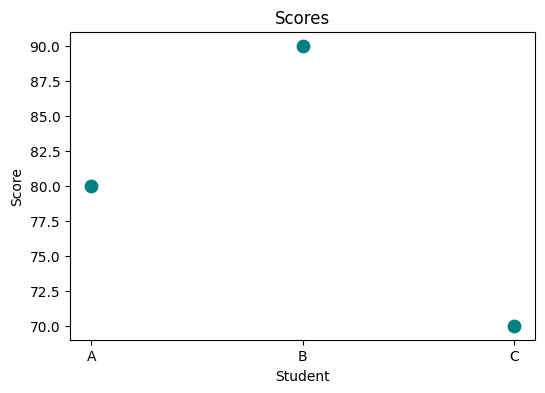

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.scatter(table["student"], table["score"], color="teal", s=80)
plt.xlabel("Student")
plt.ylabel("Score")
plt.title("Scores")
plt.savefig(output_dir / "class_scatter.png", bbox_inches="tight")
plt.show()

`figsize`设置图片大小，`color`设置颜色，`s`设置点的大小。可以先只改`color`或`s`，重新运行，观察样式变化。

#### 用柱状图比较成绩

同一组数据也能画柱状图。`bar`画柱子，`ylim(0, 100)`把纵轴显示范围定为0到100。比较图形时，先看坐标范围与单位。


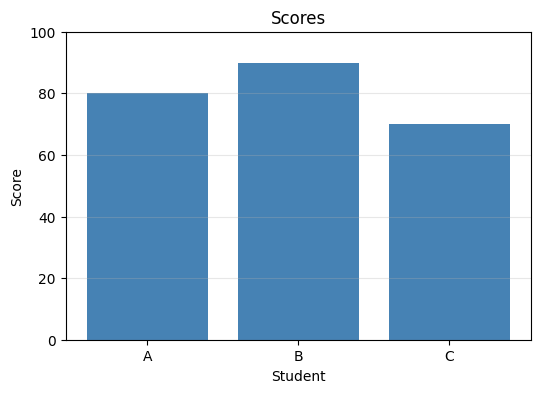

In [43]:
plt.figure(figsize=(6, 4))
plt.bar(table["student"], table["score"], color="steelblue")
plt.xlabel("Student")
plt.ylabel("Score")
plt.title("Scores")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.savefig(output_dir / "class_bar.png", bbox_inches="tight")
plt.show()

散点图用点的位置表示成绩，柱状图用柱子的高度表示成绩。这两张图的数据相同。

`grid`添加网格线，`alpha`控制透明程度。这里的英文坐标名称分别是“学生”和“成绩”。两种图都先保存，再显示，文件放在`outputs`。


#### 用直方图看数值分布

直方图把数值分成几个区间，再数每个区间里有多少项。它常用于先看成绩、尺寸等数值集中在哪些范围。


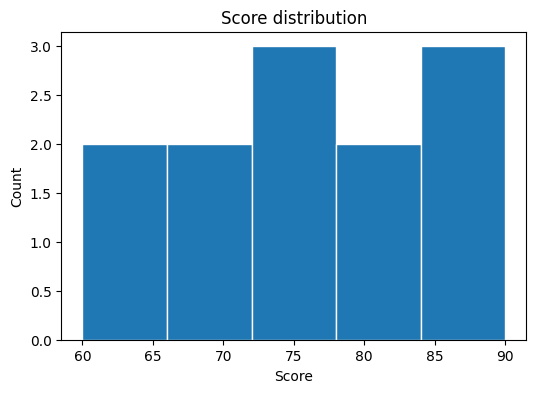

In [44]:
demo_scores = np.array([60, 65, 66, 70, 72, 74, 76, 78, 82, 85, 88, 90])
plt.figure(figsize=(6, 4))
plt.hist(demo_scores, bins=5, edgecolor="white")
plt.xlabel("Score")
plt.ylabel("Count")
plt.title("Score distribution")
plt.savefig(output_dir / "score_histogram.png", bbox_inches="tight")
plt.show()

#### 看训练与验证误差曲线

下面的数字是为认识画法手工给出的。横轴是训练轮次，纵轴是误差。训练误差继续下降、验证误差后来回升，是后续课程讨论过拟合时常看的现象。


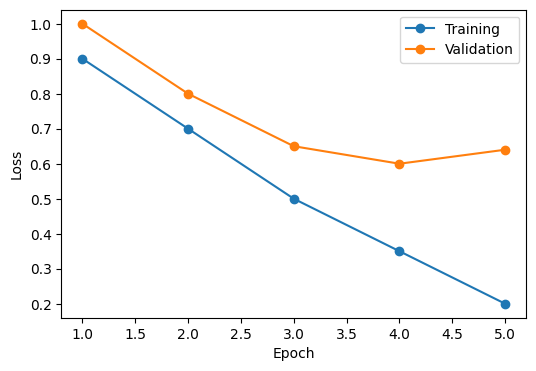

In [45]:
epochs = [1, 2, 3, 4, 5]
train_loss = [0.9, 0.7, 0.5, 0.35, 0.2]
valid_loss = [1.0, 0.8, 0.65, 0.60, 0.64]
plt.figure(figsize=(6, 4))
plt.plot(epochs, train_loss, marker="o", label="Training")
plt.plot(epochs, valid_loss, marker="o", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.savefig(output_dir / "loss_curves.png", bbox_inches="tight")
plt.show()

#### 把相关系数画成热力图

同一张相关系数表，可以用颜色表示数值大小。色条显示颜色与数值的对应关系。


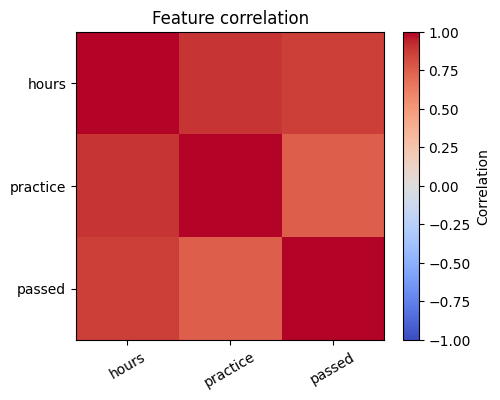

In [46]:
plt.figure(figsize=(5, 4))
plt.imshow(ml_correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(3), ml_correlation.columns, rotation=30)
plt.yticks(range(3), ml_correlation.index)
plt.colorbar(label="Correlation")
plt.title("Feature correlation")
plt.savefig(output_dir / "feature_correlation.png", bbox_inches="tight")
plt.show()

### 4. SciPy：调用统计功能

`stats.describe`计算一组数据的统计结果。可以分别读取个数、最小最大值和平均值。


In [47]:
from scipy import stats

result = stats.describe(scores)
print("个数：", result.nobs)
print("最低分：", result.minmax[0])
print("最高分：", result.minmax[1])
print("平均分：", result.mean)

个数： 3
最低分： 70
最高分： 90
平均分： 80.0


依次得到3、70、90、80.0。这些数可以直接回到原成绩核对。

#### 再用一个科学计算功能：两点距离

SciPy还提供许多其他计算。下面求平面上两点`(0,0)`与`(3,4)`的直线距离。按勾股定理，结果应为5。


In [48]:
from scipy.spatial import distance

point_a = [0, 0]
point_b = [3, 4]
print("两点距离：", distance.euclidean(point_a, point_b))

两点距离： 5.0


这里把两点坐标交给现成函数。`from ... import ...`表示从一个库的某部分取出要使用的功能。


#### 算两组点之间的距离

`cdist`可以同时计算多对距离。下面有2个查询点、3个已知点，结果是2行3列；每个位置是一对点的距离。距离越小，两点越近。


In [49]:
from scipy.spatial import distance

known_points = np.array([[0, 0], [3, 4], [6, 8]])
query_points = np.array([[0, 4], [3, 0]])
distance_table = distance.cdist(query_points, known_points, metric="euclidean")
print(distance_table)
print("结果形状：", distance_table.shape)

[[4.         3.         7.21110255]
 [3.         4.         8.54400375]]
结果形状： (2, 3)


#### 标准分与相关系数

`zscore`把数值写成“与均值相差多少个标准差”的形式，便于比较不同量纲的数据。这里先看三条成绩的结果。

`pearsonr`可以计算两组数的线性相关程度，下面读取其中的相关系数。


In [50]:
print("成绩标准分：", stats.zscore(scores))
correlation_result = stats.pearsonr([1, 2, 3, 4], [2, 4, 5, 8])
print("相关系数：", correlation_result.statistic)

成绩标准分： [ 0.          1.22474487 -1.22474487]
相关系数： 0.9811557810392122


#### 许多位置是0时：稀疏矩阵

文本词频、类别编码等数据中，经常有许多0。稀疏矩阵主要记录非零的位置和值，可以减少大量零带来的存储开销。


In [51]:
from scipy import sparse

dense_features = np.array([[1, 0, 0, 2], [0, 0, 3, 0], [1, 0, 0, 0]])
sparse_features = sparse.csr_matrix(dense_features)
print("矩阵形状：", sparse_features.shape)
print("非零个数：", sparse_features.nnz)
print("恢复为普通数组：")
print(sparse_features.toarray())

矩阵形状： (3, 4)
非零个数： 4
恢复为普通数组：
[[1 0 0 2]
 [0 0 3 0]
 [1 0 0 0]]


### 5. scikit-learn：先使用已有数据，再预测

下面仍用三对数字：1对应2、2对应4、3对应6。`fit`根据已有数据确定模型，`predict`用模型计算新输入的结果。


In [52]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit([[1], [2], [3]], [2, 4, 6])
print("输入4：", model.predict([[4]]))

输入4： [8.]


#### 一次计算多个新输入

`[[4], [5], [6]]`表示三条新记录，每条记录里只有一个输入值。


In [53]:
new_x = [4, 5, 6]
predicted = model.predict([[4], [5], [6]])
print("新输入：", new_x)
print("预测结果：", predicted)
print("直线系数：", model.coef_)
print("截距：", model.intercept_)

新输入： [4, 5, 6]
预测结果： [ 8. 10. 12.]
直线系数： [2.]
截距： 8.881784197001252e-16


预测结果约为8、10、12。这个例子中的直线可以写成`y = 2x`，因此系数约为2、截距约为0；很小的浮点数误差可以先视作0。

用Matplotlib把已知数据与预测结果画在一起：


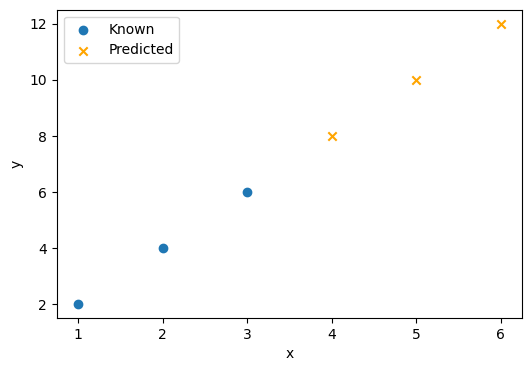

In [54]:
plt.figure(figsize=(6, 4))
plt.scatter([1, 2, 3], [2, 4, 6], label="Known")
plt.scatter(new_x, predicted, marker="x", color="orange", label="Predicted")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.savefig(output_dir / "model_prediction.png", bbox_inches="tight")
plt.show()

圆点是已知的三对数字，叉号是模型对新输入的计算结果。`legend`显示图例，说明两种点各代表什么。

这里看的是一个人为设置的简单关系；后面的课程会进一步讲怎样选择数据、训练模型和检查预测效果。


#### 机器学习的基本流程：特征、目标、训练集、测试集

用sklearn自带的鸢尾花数据继续演示，数据随库安装，运行时直接读入。

每行一朵花，四列是萼片长度、萼片宽度、花瓣长度、花瓣宽度，单位为厘米；目标是花的种类。种类用0、1、2表示，对应的英文名称可以从数据中查看。


In [55]:
from sklearn.datasets import load_iris

iris = load_iris()
iris_frame = pd.DataFrame(
    iris.data,
    columns=["sepal_length", "sepal_width", "petal_length", "petal_width"]
)
iris_frame["species"] = iris.target
display(iris_frame.head())
print("类别名称：", iris.target_names)
print("样本与列数：", iris_frame.shape)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


类别名称： ['setosa' 'versicolor' 'virginica']
样本与列数： (150, 5)


#### 先把一部分数据留出来

`X`是特征表，`y`是目标。训练集交给模型学习，测试集留到后面检查效果。

`test_size=0.25`表示约四分之一作测试集；固定`random_state`使划分可重复。`stratify`让两部分中的类别比例接近原数据。


In [56]:
from sklearn.model_selection import train_test_split

iris_X = iris_frame.drop(columns="species")
iris_y = iris_frame["species"]
X_train, X_test, y_train, y_test = train_test_split(
    iris_X, iris_y, test_size=0.25, random_state=42, stratify=iris_y
)
print("训练特征：", X_train.shape)
print("测试特征：", X_test.shape)

训练特征： (112, 4)
测试特征： (38, 4)


#### 按训练集的规则缩放特征

有的特征数值范围大，有的范围小。`StandardScaler`按训练集各列的均值与标准差进行缩放。

训练集用`fit_transform`学习规则并处理数据；测试集用`transform`沿用这个规则。


In [57]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("训练集各列均值：", np.round(X_train_scaled.mean(axis=0), 3))
print("测试集形状：", X_test_scaled.shape)

训练集各列均值： [-0. -0. -0. -0.]
测试集形状： (38, 4)


训练集缩放后的各列均值约为0。测试集不必再算一套自己的缩放规则，这样才能保持检查效果时的数据独立。

#### 用Pipeline连接预处理与模型

Pipeline把几步操作连起来。下面先缩放，再用K近邻分类；`n_neighbors=3`表示参考3个近邻。K近邻的原理在分类课继续讲。

这里交给Pipeline的是原始`X_train`，缩放由它内部完成。


In [58]:
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3))
knn_pipeline.fit(X_train, y_train)
class_prediction = knn_pipeline.predict(X_test)
print("前5个真实类别：", y_test.to_numpy()[:5])
print("前5个预测类别：", class_prediction[:5])

前5个真实类别： [0 1 1 1 0]
前5个预测类别： [0 1 1 1 0]


#### 分类效果：正确比例与混淆矩阵

准确率是预测正确的条数占总条数的比例。混淆矩阵让我们进一步看哪些类别容易混淆：行是真实类别，列是预测类别，对角线表示预测正确。


In [59]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("测试集准确率：", accuracy_score(y_test, class_prediction))
class_matrix = confusion_matrix(y_test, class_prediction)
display(pd.DataFrame(class_matrix, index=iris.target_names, columns=iris.target_names))
print(classification_report(y_test, class_prediction, target_names=iris.target_names))

测试集准确率： 0.9210526315789473


,setosa,versicolor,virginica
setosa,12,0,0
versicolor,0,13,0
virginica,0,3,10


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.81      1.00      0.90        13
   virginica       1.00      0.77      0.87        13

    accuracy                           0.92        38
   macro avg       0.94      0.92      0.92        38
weighted avg       0.94      0.92      0.92        38



报告中的precision看“预测成这一类的记录有多少是真的”，recall看“真实属于这一类的记录找回了多少”；support是该类的记录条数。先把表中数量与这些比例对应起来。


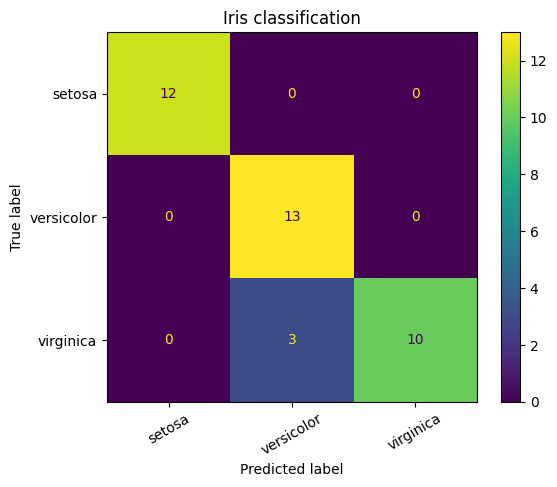

In [60]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, class_prediction, display_labels=iris.target_names, xticks_rotation=30
)
plt.title("Iris classification")
plt.savefig(output_dir / "iris_confusion_matrix.png", bbox_inches="tight")
plt.show()

#### 交叉验证：在训练数据内部多分几次

5折交叉验证把训练数据分成5份，每次轮流用一份检查，其余部分训练，得到5个结果。Pipeline中的缩放也会在每折的训练部分重新学习。

这里始终使用`X_train`、`y_train`，测试集保留作最终检查。


In [61]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(knn_pipeline, X_train, y_train, cv=5, scoring="accuracy")
print("每一折的准确率：", cv_scores)
print("平均值：", cv_scores.mean())

每一折的准确率： [1.         0.95652174 0.90909091 0.95454545 0.90909091]
平均值： 0.9458498023715414


#### 让程序比较几个参数

`GridSearchCV`在训练集内，分别尝试3、5、7个近邻，并用交叉验证比较。参数名中双下划线前面是Pipeline里模型的名字，后面是要调整的参数。


In [62]:
from sklearn.model_selection import GridSearchCV

parameter_grid = {"kneighborsclassifier__n_neighbors": [3, 5, 7]}
search = GridSearchCV(knn_pipeline, parameter_grid, cv=5, scoring="accuracy")
search.fit(X_train, y_train)
print("选中的参数：", search.best_params_)
print("训练集交叉验证平均分：", search.best_score_)
best_prediction = search.predict(X_test)
print("保留测试集的准确率：", accuracy_score(y_test, best_prediction))

选中的参数： {'kneighborsclassifier__n_neighbors': 7}
训练集交叉验证平均分： 0.9549407114624506
保留测试集的准确率： 0.9473684210526315


参数比较依据训练集内部的验证结果。测试数据用来检查模型，不用它反复挑选参数或决定填充值。

#### 数据有缺失时，把填充也放进Pipeline

下面复制训练与测试特征，各空出一个数，模拟缺失情况。`SimpleImputer`会用训练集的中位数补齐，再缩放、分类。


In [63]:
from sklearn.impute import SimpleImputer

X_train_missing = X_train.copy()
X_test_missing = X_test.copy()
X_train_missing.iloc[0, 0] = np.nan
X_test_missing.iloc[0, 1] = np.nan
missing_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)
missing_pipeline.fit(X_train_missing, y_train)
print("有缺失值时的前5个预测：", missing_pipeline.predict(X_test_missing)[:5])

有缺失值时的前5个预测： [0 1 1 1 0]


#### 回归问题：预测一个数值

分类预测种类，回归预测连续数值。仍使用鸢尾花数据，这次用萼片长度、萼片宽度和花瓣宽度预测花瓣长度。目标列从输入特征中单独拿出来。


In [64]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_reg = iris_frame[["sepal_length", "sepal_width", "petal_width"]]
y_reg = iris_frame["petal_length"]
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.25, random_state=42
)
length_model = LinearRegression()
length_model.fit(X_reg_train, y_reg_train)
length_prediction = length_model.predict(X_reg_test)
print("平均绝对误差：", mean_absolute_error(y_reg_test, length_prediction))
print("均方根误差：", np.sqrt(mean_squared_error(y_reg_test, length_prediction)))
print("R²：", r2_score(y_reg_test, length_prediction))

平均绝对误差： 0.2465941591833171
均方根误差： 0.3405546344059813
R²： 0.9658370033397268


平均绝对误差、均方根误差的单位与花瓣长度一样，都是厘米，表示预测与实际相差的程度。R²把预测误差与“用这组真实值的均值作为常数”的误差作比较，接近1表示这份数据上拟合较好，也可能出现负值。

把真实值与预测值画在一起，点越接近对角线，预测就越接近真实值。


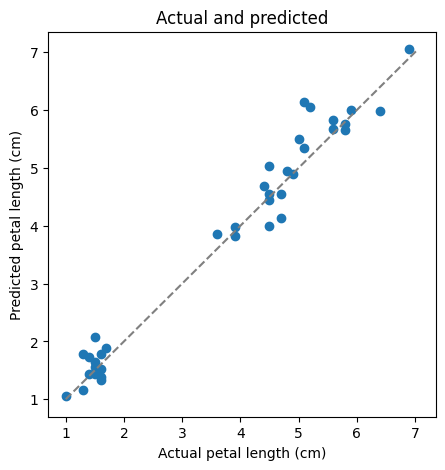

In [65]:
plt.figure(figsize=(5, 5))
plt.scatter(y_reg_test, length_prediction)
line_limits = [min(y_reg_test.min(), length_prediction.min()),
               max(y_reg_test.max(), length_prediction.max())]
plt.plot(line_limits, line_limits, "--", color="gray")
plt.xlabel("Actual petal length (cm)")
plt.ylabel("Predicted petal length (cm)")
plt.title("Actual and predicted")
plt.savefig(output_dir / "regression_actual_predicted.png", bbox_inches="tight")
plt.show()

#### 数字列和文字列一起处理

给鸢尾花特征加一列模拟来源，A、B交替出现。数字列填缺失、缩放；文字列用独热编码。`ColumnTransformer`负责把这些不同处理放在一起。


In [66]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

mixed_X = iris_X.copy()
mixed_X["source"] = ["A", "B"] * 75
X_mixed_train, X_mixed_test, y_mixed_train, y_mixed_test = train_test_split(
    mixed_X, iris_y, test_size=0.25, random_state=42, stratify=iris_y
)
numeric_columns = iris_X.columns.tolist()
numeric_steps = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
preprocess = ColumnTransformer([
    ("numbers", numeric_steps, numeric_columns),
    ("category", OneHotEncoder(handle_unknown="ignore"), ["source"])
])

`handle_unknown="ignore"`让测试时未见过的文字类别仍能进入处理流程；这类值在对应编码列中记为全0。

再把预处理与分类器连起来。`fit`从训练集确定所有处理规则，`predict`在测试集上沿用这些规则。


In [67]:
mixed_pipeline = make_pipeline(preprocess, KNeighborsClassifier(n_neighbors=3))
mixed_pipeline.fit(X_mixed_train, y_mixed_train)
mixed_prediction = mixed_pipeline.predict(X_mixed_test)
print("处理后的特征形状：", mixed_pipeline.named_steps["columntransformer"].transform(X_mixed_test).shape)
print("前5个预测：", mixed_prediction[:5])

处理后的特征形状： (38, 6)
前5个预测： [0 1 1 1 0]


#### 聚类：让数据自行分组

分类训练时有已知类别；聚类先看特征之间的相似程度，把记录分组。下面K-means分成3组，使用全部四个特征。

组号0、1、2是分组编号，与真实花种的0、1、2没有固定对应关系。


In [68]:
from sklearn.cluster import KMeans

cluster_pipeline = make_pipeline(
    StandardScaler(), KMeans(n_clusters=3, random_state=42, n_init=10)
)
cluster_labels = cluster_pipeline.fit_predict(iris_X)
print("前10条的组号：", cluster_labels[:10])
print("各组数量：", np.bincount(cluster_labels))

前10条的组号： [1 1 1 1 1 1 1 1 1 1]
各组数量： [53 50 47]


#### 降维：用两个综合坐标画出四个特征

`PCA`把多个特征组合成较少的新坐标。这里把四个特征变成两个坐标，便于画图。两根坐标轴已经是综合方向，不能当作原来的某个长度列。

颜色来自刚才的聚类结果。这个图用于观察数据分布，聚类分组是否有实际意义，还要结合问题背景判断。


降维后形状： (150, 2)


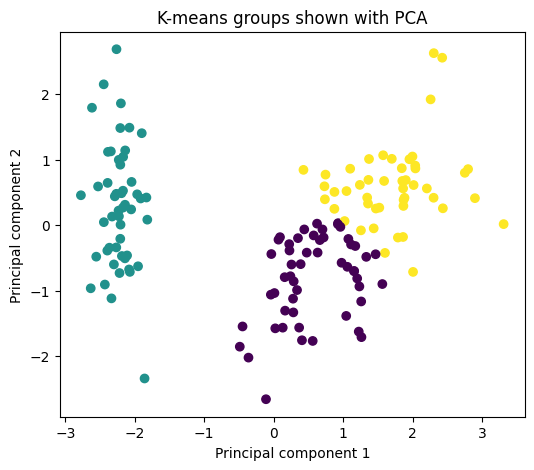

In [69]:
from sklearn.decomposition import PCA

pca_pipeline = make_pipeline(StandardScaler(), PCA(n_components=2))
points_2d = pca_pipeline.fit_transform(iris_X)
print("降维后形状：", points_2d.shape)
plt.figure(figsize=(6, 5))
plt.scatter(points_2d[:, 0], points_2d[:, 1], c=cluster_labels, cmap="viridis")
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("K-means groups shown with PCA")
plt.savefig(output_dir / "iris_cluster_pca.png", bbox_inches="tight")
plt.show()

#### 保存模型，下次继续使用

模型连同预处理一起保存，重新读取后可以继续预测。下面读取的是刚刚由本程序保存的文件；外来的模型文件应先确认来源可信。


In [70]:
import joblib

model_path = output_dir / "iris_knn_pipeline.joblib"
joblib.dump(search.best_estimator_, model_path)
loaded_pipeline = joblib.load(model_path)
loaded_prediction = loaded_pipeline.predict(X_test)
print("重新读取后的前5个预测：", loaded_prediction[:5])
print("与保存前是否相同：", np.array_equal(loaded_prediction, best_prediction))

重新读取后的前5个预测： [0 1 1 1 0]
与保存前是否相同： True


#### 一次完整操作的顺序

1. 看清一行代表什么，确定哪些列是特征、哪一列是目标。
2. 先分开训练集与测试集。
3. 在训练集上学习填充、编码、缩放规则，并训练模型。
4. 用训练集内部的验证结果比较参数。
5. 将同样的处理用于测试集，再看预测与评价结果。

数组、表格与图形都用在这个过程中。先把每一步的输入和输出对应起来，再在后续课时学习具体算法。


#### 常用文档

- NumPy数组入门：https://numpy.org/doc/stable/user/absolute_beginners.html
- pandas表格操作：https://pandas.pydata.org/docs/getting_started/intro_tutorials/
- Matplotlib绘图：https://matplotlib.org/stable/users/explain/quick_start.html
- SciPy距离计算：https://docs.scipy.org/doc/scipy/reference/spatial.distance.html
- sklearn基本流程：https://scikit-learn.org/stable/getting_started.html
- sklearn预处理与数据使用顺序：https://scikit-learn.org/stable/common_pitfalls.html


## 四、检查与回顾（5分钟）

### 保存结果

下面把成绩表保存为CSV，图片已在画图时保存。运行后到`outputs`查看这两个文件。


In [ ]:
table.to_csv(output_dir / "class_table.csv", index=False, encoding="utf-8-sig")
print("结果目录：", output_dir.resolve())

保存Notebook：本地按**Ctrl+S**，Mac按**Command+S**；和鲸使用页面的保存操作，再下载修改后的Notebook。云端结束后停止实例。

### 对照代码回答

- `score = 80`和`score == 80`各在做什么？
- `scores[0]`为什么得到第一个成绩？
- 循环中的`print`与循环外的`print`，执行次数有什么不同？
- `average(scores)`把什么交给函数，函数又返回什么？

先把这些基本写法和运行结果对应起来，再用库处理更多的数据。


## 课外阅读

### 《Python科学计算和数据分析（第3版）：使用NumPy、SciPy和Matplotlib等》

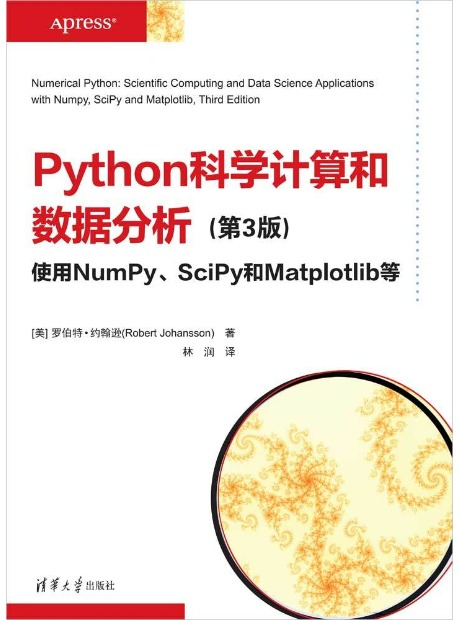

- **作者**：罗伯特·约翰逊（Robert Johansson）
- **译者**：林润（中文译本）
- **出版社**：清华大学出版社，2026年
- **ISBN**：9787302724643

这本书可配合本课复习数组、绘图和数据分析库的用法。建议先看第1章中Jupyter与Notebook的相关内容、第2章的NumPy数组，再根据学习进度查阅Matplotlib绘图、pandas数据处理和SciPy相关内容。选一两个短例子自己运行，修改其中的数据，比较输出变化。

方程求解、数值积分和代码优化等内容，可以留到后续需要时再读。

书目信息与封面来源：[清华大学出版社图书页面](https://www.tup.tsinghua.edu.cn/bookscenter/book_11155301.html)。
